<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/02_convenios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/resultado_final/notebooks/02_convenios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resultado final, notebook 02: levantamento dos convênios das prefeituras do RN

**Objetivo:** montar uma base limpa de **quanto dinheiro de convênios cada prefeitura do RN recebeu**, por ano, e salvar
em CSV para juntar com os repasses obrigatórios e as emendas no notebook 04 (junção das bases).

Este notebook substitui a análise inicial de `04_convenio.ipynb` e corrige cinco pontos dela:

| Problema na versão anterior | Correção aqui |
|---|---|
| A coluna "Município" é **onde fica** quem recebeu, não a prefeitura. Natal aparecia com R\$ 6,3 bi, mas a maior parte foi para o Governo do Estado, a UFRN, a FUNPEC etc. | Ficam só os convênios cujo convenente é a **prefeitura** ("MUNICÍPIO DE ...") |
| Entravam convênios **anulados, excluídos e cancelados** | Esses são retirados |
| Somava 1995 a 2026, **sem corrigir a inflação** | Valores em **R\$ de 2023** (IPCA), de 2004 a 2025, e um recorte 2020–2023 igual ao do projeto |
| Comparava **totais**, e as cidades grandes sempre ficavam no topo | Comparação **por habitante** |
| O "outlier" era calculado **por convênio** | A análise é **por município** |

Também incluímos os **convênios do Governo do Estado com as prefeituras**, que não estavam na versão anterior.

## Termos usados

| Termo | O que é |
|---|---|
| **Convênio** | Acordo em que um governo (União ou Estado) passa dinheiro para a prefeitura fazer **uma coisa específica**: uma obra, uma compra de equipamento, um evento. O dinheiro é "carimbado". Também entram aqui os **contratos de repasse** (o mesmo acordo, operado pela Caixa) e os **termos de compromisso** |
| **Convenente** | Quem recebe o dinheiro (aqui, a prefeitura) |
| **Concedente** | Quem dá o dinheiro (um ministério ou uma secretaria estadual) |
| **Valor celebrado** | O valor combinado no acordo |
| **Valor liberado** | O que já foi efetivamente pago à prefeitura. É a medida principal deste notebook |
| **Emenda parlamentar** | A decisão de um deputado ou senador de destinar parte do orçamento a um lugar. Ela diz **quem decidiu** mandar o dinheiro. O **caminho** do dinheiro pode ser um convênio (aí ele aparece nesta base), uma transferência especial ("emenda Pix", fora desta base) ou um repasse fundo a fundo da saúde |

**Por isso, no notebook 04 (junção):** os convênios marcados aqui como "com emenda" **não podem ser somados de novo** com a base de
emendas da colega, senão o mesmo dinheiro conta duas vezes.

## 1. Bibliotecas, estilo e funções de apoio

In [1]:
import os
import re
import json
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import requests

RAW_GITHUB = 'https://raw.githubusercontent.com/Renata-Nascimento/Projeto-U02-CD/main/'
pd.set_option('display.float_format', lambda x: f'{x:,.1f}')
pd.set_option('display.max_colwidth', 60)

AZUL, LARANJA, VERDE, AMARELO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
CINZA, CINZA_CLARO = '#a3a29b', '#d6d5d0'
TEXTO, TEXTO_2 = '#0b0b0b', '#52514e'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans',
    'axes.edgecolor': '#cccccc', 'axes.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11,
    'legend.frameon': True,
})

def reais(x, _=None):
    """Formata em reais: 1500 -> 'R$ 1,5 mil' | 2_300_000 -> 'R$ 2,3 mi'."""
    for limite, sufixo in [(1e9, ' bi'), (1e6, ' mi'), (1e3, ' mil')]:
        if abs(x) >= limite:
            v = x / limite
            texto = f'{v:.0f}' if v >= 10 else f'{v:.2f}'.rstrip('0').rstrip('.').replace('.', ',')
            return f'R$ {texto}{sufixo}'
    return f'R$ {x:.0f}'

def virgula(x, casas=1):
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

FORMATO_REAIS = mticker.FuncFormatter(reais)

def ler_csv(caminho, tentativas=3, **kwargs):
    """Lê do GitHub do projeto (tenta de novo se a conexão cair); se não conseguir, lê a cópia local (mesmo caminho)."""
    for _ in range(tentativas):
        try:
            return pd.read_csv(RAW_GITHUB + caminho, **kwargs)
        except Exception as e:
            erro = e
            if '404' in str(e):
                break
            time.sleep(3)
    if os.path.exists(caminho):
        return pd.read_csv(caminho, **kwargs)
    if '404' in str(erro):
        raise FileNotFoundError(
            f'O arquivo "{caminho}" não está no GitHub do projeto. '
            f'Suba-o para a pasta {os.path.dirname(caminho)}/ do repositório, com o mesmo nome, '
            'e rode a célula de novo.') from None
    raise ConnectionError(
        f'Não consegui baixar "{caminho}" do GitHub: o ambiente parece estar sem internet. '
        f'Erro original: {erro}') from None

def chave(nome):
    """Nome sem acento, pontuação e caixa: 'Olho-d'Água do Borges' -> 'OLHO DAGUA DO BORGES'."""
    texto = unicodedata.normalize('NFKD', str(nome)).encode('ascii', 'ignore').decode().upper().replace('-', ' ')
    return re.sub(r'\s+', ' ', re.sub(r'[^A-Z ]', '', texto)).strip()

os.makedirs('resultado_final/saida', exist_ok=True)

# Cidades em destaque, encontradas no notebook 06: recebem muito mais repasses por habitante do que as demais,
# por concentrarem parques eólicos e a produção de petróleo. Aqui servem só para marcar nos gráficos;
# a lista final sai do notebook 04, depois de juntar repasses, convênios e emendas.
CIDADES_DESTAQUE = ['Guamaré', 'São Bento do Norte', 'Pedra Grande', 'Parazinho', 'Galinhos', 'Bodó', 'Serra do Mel']

## 2. Bases de apoio: municípios, população e inflação

In [2]:
municipios = ler_csv('dados/ibge/municipios_rn.csv')[['cod_ibge', 'municipio', 'mesorregiao']]
municipios['chave'] = municipios['municipio'].map(chave)
assert municipios['chave'].is_unique and len(municipios) == 167

# População (Censo 2022) e fator do IPCA da base de repasses do notebook 01
base = ler_csv('resultado_final/saida/01_base_municipios_2020_2023.csv')
populacao = base.groupby('cod_ibge')['populacao'].mean().rename('populacao')

# Fator para levar cada ano a R$ de 2023: média do IPCA de 2023 ÷ média do IPCA do ano (mesmo método da base)
ipca = ler_csv('dados/ibge/ipca_mensal.csv')
ipca_anual = ipca.assign(ano=ipca['anomes'] // 100).groupby('ano')['ipca_indice'].mean()
FATOR_IPCA = (ipca_anual[2023] / ipca_anual).rename('fator_ipca')
assert abs(FATOR_IPCA[2020] - base.loc[base['ano'] == 2020, 'fator_ipca'].iloc[0]) < 1e-6
ANO_MAX = int(FATOR_IPCA.index.max())
print(f'IPCA disponível até {ANO_MAX}. Fatores: 2004 = {FATOR_IPCA[2004]:.2f} | 2020 = {FATOR_IPCA[2020]:.2f} | 2025 = {FATOR_IPCA[2025]:.2f}')

# Nomes que mudaram ou têm outra grafia nas bases de convênios
NOMES_ANTIGOS = {
    'ACU': 'ASSU',                       # Açu = Assú
    'ARES': 'AREZ',                      # Arês = Arez
    'AUGUSTO SEVERO': 'CAMPO GRANDE',    # nome antigo de Campo Grande
    'PRESIDENTE JUSCELINO': 'SERRA CAIADA',  # nome antigo de Serra Caiada
    'BOA SAUDE': 'JANUARIO CICCO',       # Boa Saúde = Januário Cicco
    'OLHO DAGUA DOS BORGES': 'OLHO DAGUA DO BORGES',
}

def para_cod_ibge(nomes):
    """Converte nomes de município (em qualquer grafia) para o código do IBGE."""
    chaves = nomes.map(chave).replace(NOMES_ANTIGOS)
    return chaves.map(municipios.set_index('chave')['cod_ibge'])

IPCA disponível até 2025. Fatores: 2004 = 2.87 | 2020 = 1.24 | 2025 = 0.91


## 3. Convênios federais (União → prefeituras)

**Fonte:** Portal da Transparência do Governo Federal, [Consulta de Convênios](https://portaldatransparencia.gov.br/convenios/consulta).
O arquivo `dados/emendas/convenio.csv` foi exportado de lá com o filtro **UF = RN** (botão "Baixar CSV"), com dados até
outubro de 2026. Para atualizar, repita a exportação com o mesmo filtro e substitua o arquivo no GitHub.

O arquivo traz **todos** os convênios com órgãos do RN: prefeituras, Governo do Estado, universidades, ONGs etc.

In [3]:
fed_bruto = ler_csv('dados/emendas/convenio.csv', sep=';', dtype=str)
fed_bruto = fed_bruto.loc[:, ~fed_bruto.columns.str.startswith('Unnamed')]
fed_bruto.columns = ['numero', 'uf', 'municipio_portal', 'situacao', 'tipo_instrumento', 'objeto', 'orgao_superior',
                     'orgao_vinculado', 'concedente', 'convenente', 'inicio_vigencia', 'fim_vigencia', 'publicacao',
                     'valor_liberado', 'valor_celebrado']

def moeda(coluna):
    return pd.to_numeric(coluna.str.replace('.', '', regex=False).str.replace(',', '.', regex=False), errors='coerce')

for col in ['valor_liberado', 'valor_celebrado']:
    fed_bruto[col] = moeda(fed_bruto[col])
for col in ['inicio_vigencia', 'fim_vigencia', 'publicacao']:
    fed_bruto[col] = pd.to_datetime(fed_bruto[col], format='%d/%m/%Y', errors='coerce')
fed_bruto['ano'] = fed_bruto['inicio_vigencia'].dt.year

print(f'{len(fed_bruto):,} convênios com órgãos do RN | números repetidos: {fed_bruto["numero"].duplicated().sum()}'.replace(',', '.'))
print(f'Vigência de {fed_bruto["inicio_vigencia"].min():%d/%m/%Y} a {fed_bruto["inicio_vigencia"].max():%d/%m/%Y}')

17.577 convênios com órgãos do RN | números repetidos: 0
Vigência de 03/08/1995 a 07/12/2026


### 3.1 Quem recebe: só uma parte é prefeitura

In [4]:
fed_bruto['prefeitura'] = fed_bruto['convenente'].str.upper().str.strip().str.startswith('MUNICIPIO DE')
quem_recebe = (fed_bruto.assign(quem=np.where(fed_bruto['prefeitura'], 'Prefeituras', fed_bruto['convenente'].str.upper()))
               .groupby('quem')['valor_liberado'].sum().sort_values(ascending=False))
outros = quem_recebe.drop('Prefeituras')
resumo_quem = pd.concat([quem_recebe[['Prefeituras']], outros.head(6),
                         pd.Series({'Demais órgãos e entidades': outros.iloc[6:].sum()})])
(resumo_quem.div(1e6).to_frame('Valor liberado, 1995–2026 (R$ mi, sem correção)')
 .assign(**{'% do total': resumo_quem / resumo_quem.sum() * 100}))

,"Valor liberado, 1995–2026 (R$ mi, sem correção)",% do total
Prefeituras,"3,828.3",39.7
ESTADO DO RIO GRANDE DO NORTE,"2,478.4",25.7
FUNDACAO NORTE RIO GRANDENSE DE PESQUISA E CULTURA,482.7,5.0
"SECRETARIA DE ESTADO DA EDUCACAO, DA CULTURA, DO ESPORTE E DO LAZER (SEEC)",332.2,3.4
SECRETARIA DE ESTADO DA SEGURANCA PUBLICA E DA DEFESA SOCIAL,229.5,2.4
INSTITUTO DE ASSISTENCIA TECNICA E EXTENSAO RURAL DO RIO GRANDE DO NORTE,214.2,2.2
UNIVERSIDADE FEDERAL DO RIO GRANDE DO NORTE,193.6,2.0
Demais órgãos e entidades,"1,880.3",19.5


**Leitura:** só cerca de **40% do dinheiro** dos convênios federais no RN foi para prefeituras. O maior recebedor isolado é
o **Governo do Estado**. Na versão anterior, tudo isso era contado no município onde fica o órgão, e por isso Natal
aparecia com valores tão altos.

### 3.2 Limpeza passo a passo

In [5]:
SITUACOES_FORA = ['CONVÊNIO ANULADO', 'EXCLUÍDO', 'CANCELADO', 'RESCINDIDO']

passos = [('Todos os convênios com órgãos do RN', fed_bruto)]
fed = fed_bruto[fed_bruto['prefeitura']].copy()
passos.append(('Só prefeituras', fed))
fed = fed[~fed['situacao'].str.upper().isin(SITUACOES_FORA)]
passos.append(('Sem anulados, excluídos, cancelados e rescindidos', fed))
fed = fed[fed['ano'].between(2004, ANO_MAX)].copy()
passos.append((f'Início da vigência entre 2004 e {ANO_MAX}', fed))

funil = pd.DataFrame([{'Passo': nome, 'Convênios': len(t), 'Valor liberado (R$ mi, sem correção)': t['valor_liberado'].sum() / 1e6,
                       'Valor celebrado (R$ mi, sem correção)': t['valor_celebrado'].sum() / 1e6} for nome, t in passos]).set_index('Passo')
print('Situações retiradas:', fed_bruto[fed_bruto['prefeitura'] & fed_bruto['situacao'].str.upper().isin(SITUACOES_FORA)]
      .groupby('situacao').size().to_dict())
funil

Situações retiradas: {'CANCELADO': 26, 'CONVÊNIO ANULADO': 481, 'EXCLUÍDO': 524, 'RESCINDIDO': 7}


,Convênios,"Valor liberado (R$ mi, sem correção)","Valor celebrado (R$ mi, sem correção)"
Passo,,,
Todos os convênios com órgãos do RN,17577,"9,639.4","13,260.4"
Só prefeituras,13297,"3,828.3","5,999.4"
"Sem anulados, excluídos, cancelados e rescindidos",12259,"3,817.4","5,680.1"
Início da vigência entre 2004 e 2025,8027,"3,370.1","4,986.1"


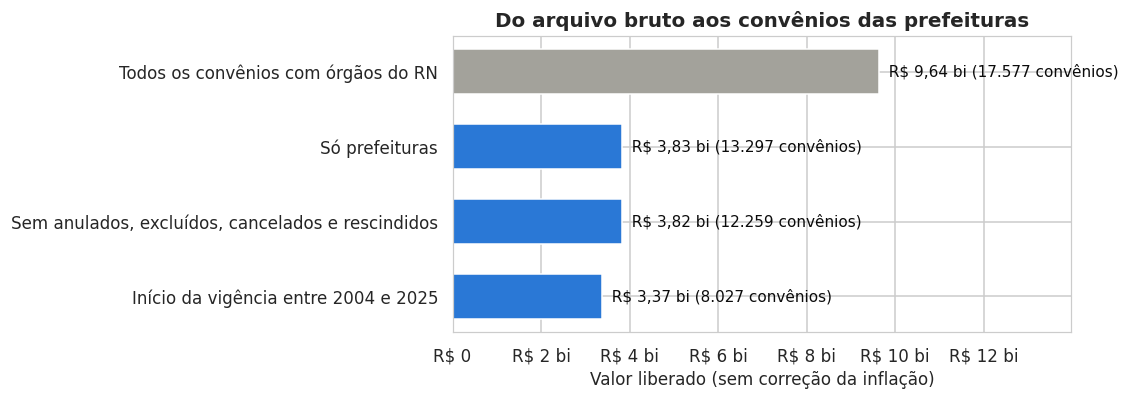

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
y = np.arange(len(funil))[::-1]
ax.barh(y, funil['Valor liberado (R$ mi, sem correção)'] * 1e6, color=[CINZA, AZUL, AZUL, AZUL], height=0.6)
for yi, (nome, linha) in zip(y, funil.iterrows()):
    ax.text(linha['Valor liberado (R$ mi, sem correção)'] * 1e6, yi,
            f'  {reais(linha["Valor liberado (R$ mi, sem correção)"] * 1e6)} ({virgula(linha["Convênios"], 0)} convênios)',
            va='center', fontsize=10, color=TEXTO)
ax.set_yticks(y)
ax.set_yticklabels(funil.index)
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, funil.iloc[0, 1] * 1e6 * 1.45)
ax.set_xlabel('Valor liberado (sem correção da inflação)')
ax.set_title('Do arquivo bruto aos convênios das prefeituras')
plt.tight_layout()
plt.show()

### 3.3 Município, área e emenda

- **Município:** usamos o nome do Portal e convertemos para o código do IBGE. Cinco municípios aparecem com nome antigo ou
  outra grafia (ver `NOMES_ANTIGOS`).
- **Área:** agrupamos pelo ministério que deu o dinheiro.
- **Emenda:** o arquivo `dados/emendas/EmendasParlamentares_Convenios.csv` (Portal da Transparência, Brasil inteiro) liga
  cada emenda ao número do convênio. Marcamos como **"com emenda"** os convênios que aparecem nele. Esse arquivo só tem
  emendas **a partir de 2015** (convênios publicados desde 2014), então a marcação vale só para convênios iniciados de
  2014 em diante. Antes disso, todos ficam como "sem emenda ligada", o que não quer dizer que não tinham emenda.
- **Atenção:** "com emenda" quer dizer que o convênio **recebeu pelo menos uma emenda**, e não que todo o valor veio de
  emenda. Exemplo: grandes convênios de obras começados em 2014 em Parnamirim, Natal e Extremoz receberam emendas só em
  2020, e o valor inteiro deles fica marcado. Por isso a fatia "com emenda" é um **teto**: a parte paga por emenda é
  menor ou igual a ela.

In [7]:
fed['cod_ibge'] = para_cod_ibge(fed['municipio_portal'])
sem_codigo = fed.loc[fed['cod_ibge'].isna(), 'municipio_portal'].unique()
assert len(sem_codigo) == 0, f'municípios sem código: {sem_codigo}'
fed['cod_ibge'] = fed['cod_ibge'].astype(int)

AREA_MINISTERIO = {
    'Ministério da Saúde': 'Saúde',
    'Ministério da Educação': 'Educação',
    'Ministério das Cidades': 'Infraestrutura e cidades',
    'Ministério da Integração e do Desenvolvimento Regional': 'Infraestrutura e cidades',
    'Ministério do Turismo': 'Turismo, esporte e cultura',
    'Ministério do Esporte': 'Turismo, esporte e cultura',
    'Ministério da Cultura': 'Turismo, esporte e cultura',
    'Ministério da Agricultura e Pecuária': 'Agricultura',
    'Ministério do Desenvolvimento Agrário e Agricultura Familiar': 'Agricultura',
    'Ministério da Pesca e Aquicultura': 'Agricultura',
    'Ministério do Desenvolvimento e Assistência Social, Família e Combate à Fome': 'Assistência social',
}
fed['area'] = fed['orgao_superior'].map(AREA_MINISTERIO).fillna('Outras áreas')

emendas_conv = ler_csv('dados/emendas/EmendasParlamentares_Convenios.csv', sep=';', encoding='latin1', dtype=str)
numeros_com_emenda = set(emendas_conv['Número Convênio'].str.strip())
fed['com_emenda'] = fed['numero'].str.strip().isin(numeros_com_emenda) & (fed['ano'] >= 2014)

fed['fator_ipca'] = fed['ano'].map(FATOR_IPCA)
fed['liberado_real'] = fed['valor_liberado'] * fed['fator_ipca']
fed['celebrado_real'] = fed['valor_celebrado'] * fed['fator_ipca']
print(f'{fed["cod_ibge"].nunique()} municípios com convênio federal | '
      f'{fed.loc[fed["ano"] >= 2014, "com_emenda"].mean() * 100:.0f}% dos convênios iniciados desde 2014 têm emenda ligada')

167 municípios com convênio federal | 57% dos convênios iniciados desde 2014 têm emenda ligada


## 4. Convênios estaduais (Governo do RN → prefeituras)

**Fonte:** Controladoria-Geral do Estado, [Consulta de Convênios](http://convenios.control.rn.gov.br/conveniorelsite.aspx)
(o link "Convênios concedidos" do Portal da Transparência do RN). Filtros: **beneficiário = Prefeituras** e **período de
abertura**, ano a ano, de 2015 a 2025.

A consulta demora e às vezes cai, então lemos a cópia salva em `dados/convenios/`. Para baixar de novo, mude
`BAIXAR_ESTADO` para `True`.

Cada convênio tem uma lista de **eventos**: abertura, aditivo, anulação, prorrogação e prestação de contas. Esse sistema
**não informa o valor liberado**, então o valor do convênio estadual é **abertura + aditivos − anulações** (o valor
combinado).

In [8]:
BAIXAR_ESTADO = False
URL_ESTADO = 'http://convenios.control.rn.gov.br/conveniorelsite.aspx'

def baixar_estado(ano):
    """Consulta os convênios do Estado com prefeituras abertos em um ano."""
    sessao = requests.Session()
    html = sessao.get(URL_ESTADO, timeout=60).text
    campos = {n: re.search(rf'id="{n}" value="([^"]*)"', html).group(1)
              for n in ['__VIEWSTATE', '__VIEWSTATEGENERATOR', '__EVENTVALIDATION']}
    formulario = {**campos, '__EVENTTARGET': 'btnConsultar', '__EVENTARGUMENT': '', 'txtCNPJ': '', 'txtNome': '',
                  'chkBeneficiariosMunicipios': 'on', 'txtDataAberturaIni': f'01/01/{ano}',
                  'txtDataAberturaFin': f'31/12/{ano}', 'txtDataVigenteIni': '', 'txtDataVigenteFin': '', 'ddlOrgaos': '0'}
    resposta = sessao.post(URL_ESTADO, data=formulario, timeout=600).text
    fim = resposta.rfind(';NovoTabulator(data)')
    if fim < 0:
        return []
    inicio = list(re.finditer(r'data\s*=\s*\[', resposta[:fim]))[-1].end() - 1
    return json.loads(resposta[inicio:fim])

if BAIXAR_ESTADO:
    lista = [c for ano in range(2015, 2026) for c in baixar_estado(ano)]
    est_conv = pd.DataFrame([{k: c[k] for k in ['Id', 'NumeroConvenio', 'Exercicio', 'OrgaoConcedente', 'CnpjBeneficiario',
                                                'NomeBeneficiario', 'Objeto', 'Observacao', 'Saldo']} for c in lista]).drop_duplicates('Id')
    est_eventos = pd.DataFrame([{'Id': c['Id'], **e} for c in lista for e in c['Eventos']]).drop_duplicates()
    est_conv.to_csv('dados/convenios/convenios_estado_prefeituras_2015_2025.csv', index=False)
    est_eventos.to_csv('dados/convenios/convenios_estado_prefeituras_eventos.csv', index=False)
else:
    est_conv = ler_csv('dados/convenios/convenios_estado_prefeituras_2015_2025.csv')
    est_eventos = ler_csv('dados/convenios/convenios_estado_prefeituras_eventos.csv')

print(f'{len(est_conv)} convênios | {len(est_eventos)} eventos')
est_eventos.groupby('Nome')['Valor'].agg(['count', 'sum']).rename(columns={'count': 'Eventos', 'sum': 'Valor (R$)'})

619 convênios | 2982 eventos


,Eventos,Valor (R$)
Nome,,
Abertura,650,"203,207,277.1"
Aditivo,125,"42,064,131.5"
Anulação,52,"5,607,169.9"
Anulação Contra-Partida,29,"8,010,637.2"
Dever Prestar Contas,221,0.0
Prestação de Contas,343,"77,487,124.3"
Prorrogação,1562,300.0


In [9]:
SINAL = {'Abertura': 1, 'Aditivo': 1, 'Anulação': -1}
est_eventos['data'] = pd.to_datetime(est_eventos['DataProcesso'], format='%d/%m/%Y', errors='coerce')
valor_est = (est_eventos[est_eventos['Nome'].isin(SINAL)]
             .assign(v=lambda t: t['Valor'] * t['Nome'].map(SINAL))
             .groupby('Id')['v'].sum().rename('valor_conveniado'))
ano_abertura = est_eventos[est_eventos['Nome'] == 'Abertura'].groupby('Id')['data'].min().dt.year.rename('ano')

est = est_conv.set_index('Id').join([valor_est, ano_abertura]).reset_index()
est['municipio_nome'] = est['NomeBeneficiario'].str.replace(r'^(PREFEITURA MUNICIPAL|PREFEITURA|MUNICIPIO) D[EOA]S? ', '',
                                                            regex=True, case=False)
est['cod_ibge'] = para_cod_ibge(est['municipio_nome'])
assert est['cod_ibge'].notna().all(), est.loc[est['cod_ibge'].isna(), 'NomeBeneficiario'].unique()
est['cod_ibge'] = est['cod_ibge'].astype(int)

AREA_SECRETARIA = {'SESAP': 'Saúde', 'SECD': 'Educação', 'SEEC': 'Educação', 'SIN': 'Infraestrutura e cidades',
                   'CEHAB': 'Infraestrutura e cidades', 'EMPROTUR': 'Turismo, esporte e cultura',
                   'EMPROTURN': 'Turismo, esporte e cultura', 'FJA': 'Turismo, esporte e cultura',
                   'SEEL': 'Turismo, esporte e cultura', 'SAPE': 'Agricultura', 'SETHAS': 'Assistência social'}
est['area'] = est['OrgaoConcedente'].str.extract(r'^(\w+)')[0].map(AREA_SECRETARIA).fillna('Outras áreas')
est = est[est['ano'].between(2015, ANO_MAX) & (est['valor_conveniado'] > 0)].copy()
est['valor_real'] = est['valor_conveniado'] * est['ano'].map(FATOR_IPCA)
print(f'{len(est)} convênios estaduais com valor | {est["cod_ibge"].nunique()} municípios')

602 convênios estaduais com valor | 134 municípios


## 5. Visão geral

**Sobre o ano:** o valor liberado do Portal é o **total acumulado** do convênio, e não o que foi pago em cada ano. Por
isso, cada convênio é contado no **ano em que começou** (início da vigência no federal, abertura no estadual). Um
convênio de 2019 pago em 2021 conta em 2019. No notebook 04 (junção), vale conferir com o SICONFI, onde cada prefeitura declara
quanto recebeu de convênios em cada ano.

### 5.1 Por ano

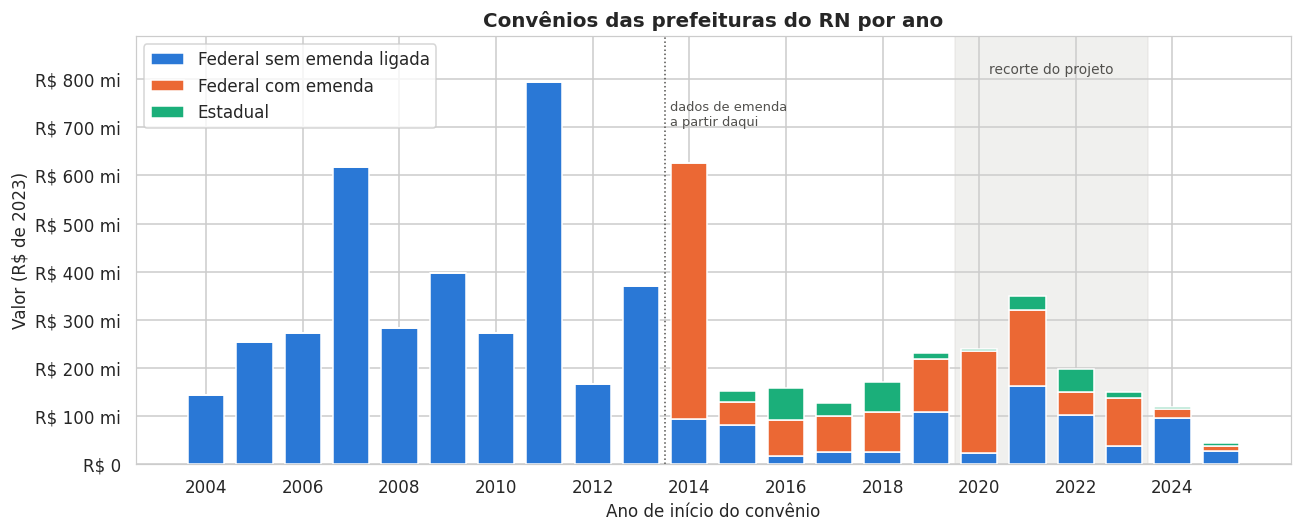

Convênios estaduais só existem no sistema a partir de 2015. Os anos finais ainda estão sendo pagos (o valor liberado de convênios recentes ainda vai crescer).


,Federal com emenda,Federal sem emenda ligada,Estadual
ano,,,
2016,74.1,17.7,67.7
2017,73.1,26.4,27.3
2018,82.3,26.6,62.3
2019,110.9,108.2,11.2
2020,212.4,22.7,4.2
2021,156.6,163.3,29.6
2022,46.6,103.1,49.0
2023,99.3,37.7,13.6
2024,19.9,95.3,4.1


In [10]:
por_ano = pd.DataFrame({
    'Federal com emenda': fed[fed['com_emenda']].groupby('ano')['liberado_real'].sum(),
    'Federal sem emenda ligada': fed[~fed['com_emenda']].groupby('ano')['liberado_real'].sum(),
    'Estadual': est.groupby('ano')['valor_real'].sum(),
}).fillna(0).loc[2004:ANO_MAX]

fig, ax = plt.subplots(figsize=(12, 5))
fundo = np.zeros(len(por_ano))
for col, cor in [('Federal sem emenda ligada', AZUL), ('Federal com emenda', LARANJA), ('Estadual', VERDE)]:
    ax.bar(por_ano.index, por_ano[col], bottom=fundo, color=cor, label=col, width=0.75, edgecolor='white', linewidth=1)
    fundo += por_ano[col].values
ax.axvspan(2019.5, 2023.5, color=CINZA_CLARO, alpha=0.35, zorder=0)
ax.axvline(2013.5, color=TEXTO_2, linestyle=':', linewidth=1)
ax.text(2013.6, fundo.max() * 0.95, 'dados de emenda\na partir daqui', fontsize=8.5, color=TEXTO_2, va='top')
ax.text(2021.5, fundo.max() * 1.02, 'recorte do projeto', ha='center', fontsize=9, color=TEXTO_2)
ax.yaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xticks(por_ano.index[::2])
ax.set_ylim(0, fundo.max() * 1.12)
ax.set_xlabel('Ano de início do convênio')
ax.set_ylabel('Valor (R$ de 2023)')
ax.set_title('Convênios das prefeituras do RN por ano')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print('Convênios estaduais só existem no sistema a partir de 2015. Os anos finais ainda estão sendo pagos '
      '(o valor liberado de convênios recentes ainda vai crescer).')
(por_ano.loc[2016:].div(1e6)).round(1)

### 5.2 Por área (2020–2023)

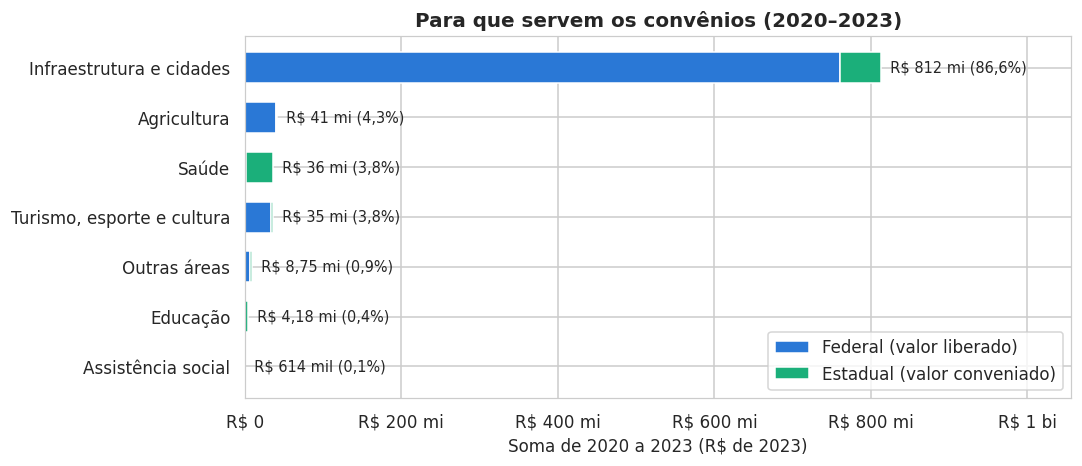

,Federal (valor liberado),Estadual (valor conveniado),Total,% do total
area,,,,
Infraestrutura e cidades,759.9,52.6,812.4,86.6
Agricultura,40.2,0.5,40.8,4.3
Saúde,1.2,34.8,36.1,3.8
"Turismo, esporte e cultura",33.1,2.3,35.3,3.8
Outras áreas,6.8,2.0,8.8,0.9
Educação,0.0,4.2,4.2,0.4
Assistência social,0.6,0.0,0.6,0.1


In [11]:
recorte_fed = fed[fed['ano'].between(2020, 2023)]
recorte_est = est[est['ano'].between(2020, 2023)]
por_area = pd.DataFrame({
    'Federal (valor liberado)': recorte_fed.groupby('area')['liberado_real'].sum(),
    'Estadual (valor conveniado)': recorte_est.groupby('area')['valor_real'].sum(),
}).fillna(0)
por_area['Total'] = por_area.sum(axis=1)
por_area = por_area.sort_values('Total')

fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(por_area))
ax.barh(y, por_area['Federal (valor liberado)'], height=0.62, color=AZUL, label='Federal (valor liberado)')
ax.barh(y, por_area['Estadual (valor conveniado)'], left=por_area['Federal (valor liberado)'], height=0.62, color=VERDE,
        label='Estadual (valor conveniado)', edgecolor='white', linewidth=1)
participacao = por_area['Total'] / por_area['Total'].sum() * 100
for yi, (total, pct) in zip(y, zip(por_area['Total'], participacao)):
    ax.text(total, yi, f'  {reais(total)} ({virgula(pct)}%)', va='center', fontsize=9.5)
ax.set_yticks(y)
ax.set_yticklabels(por_area.index)
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, por_area['Total'].max() * 1.3)
ax.set_xlabel('Soma de 2020 a 2023 (R$ de 2023)')
ax.set_title('Para que servem os convênios (2020–2023)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

(por_area.iloc[::-1].div(1e6)
 .assign(**{'% do total': por_area['Total'].iloc[::-1] / por_area['Total'].sum() * 100}))

### 5.3 Quanto vem de emenda (federal, 2020–2023)

In [12]:
emenda = (recorte_fed.groupby('com_emenda')['liberado_real'].agg(['size', 'sum'])
          .rename(index={True: 'Com emenda parlamentar', False: 'Sem emenda ligada'}, columns={'size': 'Convênios', 'sum': 'Valor liberado'}))
emenda['% do valor'] = emenda['Valor liberado'] / emenda['Valor liberado'].sum() * 100
emenda['Valor liberado'] = emenda['Valor liberado'].map(reais)
emenda

,Convênios,Valor liberado,% do valor
com_emenda,,,
Sem emenda ligada,427,R$ 327 mi,38.8
Com emenda parlamentar,559,R$ 515 mi,61.2


## 6. Por município (2020–2023)

Para cada município: soma de 2020 a 2023 em R$ de 2023, e a **média por ano por habitante**, comparável ao repasse por
habitante do notebook 01.

In [13]:
def soma_por_municipio(tabela, coluna, prefixo):
    agrupado = tabela.groupby('cod_ibge')
    return pd.DataFrame({f'{prefixo}_n': agrupado.size(), f'{prefixo}_valor': agrupado[coluna].sum()})

mun = municipios.set_index('cod_ibge')[['municipio', 'mesorregiao']].join(populacao)
mun = mun.join(soma_por_municipio(recorte_fed, 'liberado_real', 'fed'))
mun = mun.join(recorte_fed[recorte_fed['com_emenda']].groupby('cod_ibge')['liberado_real'].sum().rename('fed_com_emenda_valor'))
mun = mun.join(soma_por_municipio(recorte_est, 'valor_real', 'est'))
for area in ['Saúde', 'Educação', 'Infraestrutura e cidades']:
    sufixo = chave(area).split()[0].lower()
    mun = mun.join(pd.concat([recorte_fed[recorte_fed['area'] == area].groupby('cod_ibge')['liberado_real'].sum(),
                              recorte_est[recorte_est['area'] == area].groupby('cod_ibge')['valor_real'].sum()], axis=1)
                   .sum(axis=1).rename(f'total_{sufixo}_valor'))
mun = mun.fillna(0)
mun['fed_sem_emenda_valor'] = mun['fed_valor'] - mun['fed_com_emenda_valor']
mun['total_valor'] = mun['fed_valor'] + mun['est_valor']
for col in ['fed_valor', 'fed_com_emenda_valor', 'fed_sem_emenda_valor', 'est_valor', 'total_valor']:
    mun[col.replace('_valor', '_pc_ano')] = mun[col] / mun['populacao'] / 4
mun['posicao_convenios'] = mun['total_pc_ano'].rank(ascending=False, method='min').astype(int)

print(f'Municípios sem nenhum convênio federal iniciado em 2020–2023: {(mun["fed_n"] == 0).sum()} | '
      f'sem convênio estadual: {(mun["est_n"] == 0).sum()}')
print(f'Mediana por habitante por ano: federal R$ {mun["fed_pc_ano"].median():,.0f} | estadual R$ {mun["est_pc_ano"].median():,.0f} | '
      f'total R$ {mun["total_pc_ano"].median():,.0f}')
mun.sort_values('total_pc_ano', ascending=False)[['municipio', 'populacao', 'fed_n', 'est_n', 'fed_pc_ano', 'est_pc_ano',
                                                   'total_pc_ano']].head(15)

Municípios sem nenhum convênio federal iniciado em 2020–2023: 4 | sem convênio estadual: 91
Mediana por habitante por ano: federal R$ 59 | estadual R$ 0 | total R$ 74


,municipio,populacao,fed_n,est_n,fed_pc_ano,est_pc_ano,total_pc_ano
cod_ibge,,,,,,,
2404101,Galinhos,"2,104.0",3.0,0.0,876.6,0.0,876.6
2400109,Acari,"10,597.0",6.0,3.0,672.0,21.9,693.9
2410702,Riacho da Cruz,"2,701.0",5.0,0.0,542.1,0.0,542.1
2414308,Timbaúba dos Batistas,"2,348.0",5.0,1.0,353.1,54.6,407.7
2404853,Itajá,"7,292.0",7.0,0.0,393.6,0.0,393.6
2407609,Messias Targino,"4,274.0",7.0,0.0,359.6,0.0,359.6
2409506,Pedra Grande,"3,618.0",8.0,1.0,294.6,51.8,346.4
2407500,Maxaranguape,"10,255.0",14.0,0.0,332.9,0.0,332.9
2406908,Lucrécia,"3,490.0",5.0,1.0,295.9,24.7,320.7


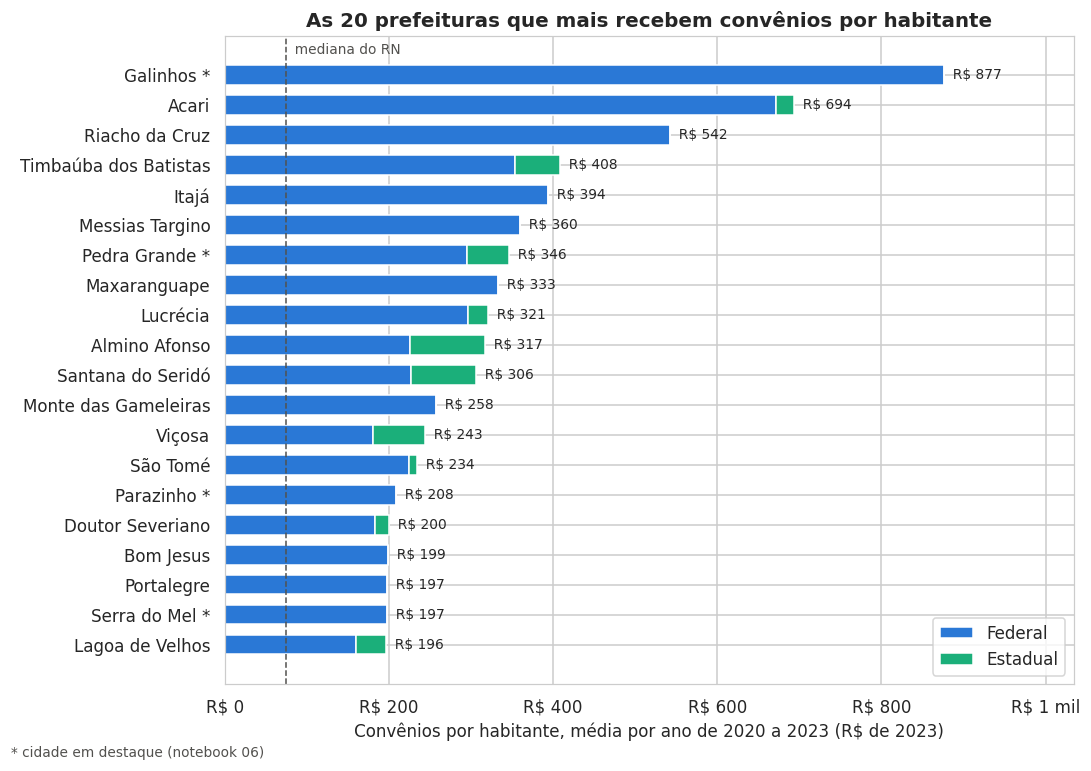

In [14]:
top = mun.sort_values('total_pc_ano', ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(top))
ax.barh(y, top['fed_pc_ano'], color=AZUL, height=0.65, label='Federal')
ax.barh(y, top['est_pc_ano'], left=top['fed_pc_ano'], color=VERDE, height=0.65, label='Estadual')
for yi, (cod, linha) in zip(y, top.iterrows()):
    ax.text(linha['total_pc_ano'], yi, f'  R$ {linha["total_pc_ano"]:,.0f}'.replace(',', '.'), va='center', fontsize=9)
ax.axvline(mun['total_pc_ano'].median(), color=TEXTO_2, linestyle='--', linewidth=1)
ax.text(mun['total_pc_ano'].median(), len(top) - 0.3, '  mediana do RN', fontsize=9, color=TEXTO_2)
ax.set_yticks(y)
ax.set_yticklabels([f'{m} *' if m in CIDADES_DESTAQUE else m for m in top['municipio']])
ax.xaxis.set_major_formatter(FORMATO_REAIS)
ax.set_xlim(0, top['total_pc_ano'].max() * 1.18)
ax.set_xlabel('Convênios por habitante, média por ano de 2020 a 2023 (R$ de 2023)')
ax.set_title('As 20 prefeituras que mais recebem convênios por habitante')
ax.legend(loc='lower right')
fig.text(0.01, 0.005, '* cidade em destaque (notebook 06)', fontsize=9, color=TEXTO_2)
plt.tight_layout()
plt.show()

### 6.1 E as cidades em destaque?

In [15]:
mun.loc[mun['municipio'].isin(CIDADES_DESTAQUE)].set_index('municipio')[
    ['fed_n', 'est_n', 'fed_pc_ano', 'est_pc_ano', 'total_pc_ano', 'posicao_convenios']
].sort_values('posicao_convenios').rename(columns={
    'fed_n': 'Convênios federais', 'est_n': 'Convênios estaduais', 'fed_pc_ano': 'Federal (R$/hab/ano)',
    'est_pc_ano': 'Estadual (R$/hab/ano)', 'total_pc_ano': 'Total (R$/hab/ano)', 'posicao_convenios': 'Posição no RN (de 167)'})

,Convênios federais,Convênios estaduais,Federal (R$/hab/ano),Estadual (R$/hab/ano),Total (R$/hab/ano),Posição no RN (de 167)
municipio,,,,,,
Galinhos,3.0,0.0,876.6,0.0,876.6,1
Pedra Grande,8.0,1.0,294.6,51.8,346.4,7
Parazinho,6.0,0.0,208.2,0.0,208.2,15
Serra do Mel,5.0,0.0,197.1,0.0,197.1,19
São Bento do Norte,2.0,0.0,170.4,0.0,170.4,24
Bodó,6.0,0.0,106.2,0.0,106.2,51
Guamaré,1.0,0.0,0.0,0.0,0.0,164


## 7. Arquivos finais

| Arquivo | Conteúdo |
|---|---|
| `resultado_final/saida/02_convenios_municipio_ano.csv` | Uma linha por **município, ano, fonte e área**, de 2004 (federal) e 2015 (estadual) a 2025: número de convênios, valores sem correção e em R\$ de 2023, e a parte com emenda |
| `resultado_final/saida/02_convenios_municipios_2020_2023.csv` | Uma linha por **município** (os 167, inclusive os que não receberam nada), com as somas de 2020 a 2023 e os valores por habitante por ano. É o que vai para o notebook 04 (junção) |

No Colab, os arquivos ficam na pasta `resultado_final/saida/` do painel de arquivos (ícone de pasta à esquerda): baixe e
suba para a pasta `resultado_final/saida/` do repositório.

In [16]:
fed['liberado_real_com_emenda'] = fed['liberado_real'].where(fed['com_emenda'], 0)
longo_fed = (fed.groupby(['cod_ibge', 'ano', 'area'])
             .agg(n_convenios=('numero', 'size'), valor_celebrado=('valor_celebrado', 'sum'),
                  valor_liberado=('valor_liberado', 'sum'), valor_liberado_real=('liberado_real', 'sum'),
                  valor_liberado_real_com_emenda=('liberado_real_com_emenda', 'sum'))
             .reset_index().assign(fonte='federal'))
longo_est = (est.groupby(['cod_ibge', 'ano', 'area'])
             .agg(n_convenios=('Id', 'size'), valor_celebrado=('valor_conveniado', 'sum'),
                  valor_liberado_real=('valor_real', 'sum'))
             .reset_index().assign(fonte='estadual', valor_liberado=np.nan, valor_liberado_real_com_emenda=np.nan))
longo = (pd.concat([longo_fed, longo_est], ignore_index=True)
         .merge(municipios[['cod_ibge', 'municipio']], on='cod_ibge')
         [['cod_ibge', 'municipio', 'ano', 'fonte', 'area', 'n_convenios', 'valor_celebrado', 'valor_liberado',
           'valor_liberado_real', 'valor_liberado_real_com_emenda']]
         .sort_values(['cod_ibge', 'ano', 'fonte', 'area']))
longo.to_csv('resultado_final/saida/02_convenios_municipio_ano.csv', index=False)

final = mun.reset_index()[['cod_ibge', 'municipio', 'mesorregiao', 'populacao', 'fed_n', 'est_n', 'fed_valor',
                           'fed_com_emenda_valor', 'fed_sem_emenda_valor', 'est_valor', 'total_valor',
                           'total_saude_valor', 'total_educacao_valor', 'total_infraestrutura_valor',
                           'fed_pc_ano', 'fed_com_emenda_pc_ano', 'fed_sem_emenda_pc_ano', 'est_pc_ano', 'total_pc_ano',
                           'posicao_convenios']]
final.to_csv('resultado_final/saida/02_convenios_municipios_2020_2023.csv', index=False)
print(f'convenios_municipio_ano.csv: {len(longo):,} linhas | convenios_municipios_2020_2023.csv: {len(final)} municípios'.replace(',', '.'))

# Conferência: os totais dos arquivos batem com as bases limpas
assert abs(longo.loc[longo['fonte'] == 'federal', 'valor_liberado_real'].sum() - fed['liberado_real'].sum()) < 1
assert abs(final['fed_valor'].sum() - recorte_fed['liberado_real'].sum()) < 1
assert abs(final['est_valor'].sum() - recorte_est['valor_real'].sum()) < 1
final.head()

convenios_municipio_ano.csv: 5.549 linhas | convenios_municipios_2020_2023.csv: 167 municípios


,cod_ibge,municipio,mesorregiao,populacao,fed_n,est_n,fed_valor,fed_com_emenda_valor,fed_sem_emenda_valor,est_valor,total_valor,total_saude_valor,total_educacao_valor,total_infraestrutura_valor,fed_pc_ano,fed_com_emenda_pc_ano,fed_sem_emenda_pc_ano,est_pc_ano,total_pc_ano,posicao_convenios
0,2400109,Acari,Central Potiguar,"10,597.0",6.0,3.0,"28,482,923.6","28,209,911.3","273,012.3","928,742.7","29,411,666.3",0.0,0.0,"28,887,544.7",672.0,665.5,6.4,21.9,693.9,2
1,2400208,Assú,Oeste Potiguar,"56,496.0",5.0,0.0,"6,396,762.1","1,959,475.1","4,437,287.0",0.0,"6,396,762.1",0.0,0.0,"2,183,838.0",28.3,8.7,19.6,0.0,28.3,140
2,2400307,Afonso Bezerra,Central Potiguar,"10,839.0",9.0,1.0,"3,221,588.7","777,036.8","2,444,551.9","97,483.6","3,319,072.4","97,483.6",0.0,"2,377,459.3",74.3,17.9,56.4,2.2,76.6,82
3,2400406,Água Nova,Oeste Potiguar,"2,946.0",4.0,1.0,"723,235.8","723,235.8",0.0,"471,852.4","1,195,088.2",0.0,0.0,"781,324.3",61.4,61.4,0.0,40.0,101.4,58
4,2400505,Alexandria,Oeste Potiguar,"13,640.0",8.0,0.0,"5,484,221.1","3,772,605.7","1,711,615.4",0.0,"5,484,221.1",0.0,0.0,"5,156,751.7",100.5,69.1,31.4,0.0,100.5,60


**Dicionário do `convenios_municipios_2020_2023.csv`** (valores somados de 2020 a 2023, em R\$ de 2023):

| Coluna | O que é |
|---|---|
| `fed_n`, `est_n` | Número de convênios federais e estaduais iniciados no período |
| `fed_valor` | Valor liberado dos convênios federais |
| `fed_com_emenda_valor`, `fed_sem_emenda_valor` | A parte federal com e sem emenda parlamentar ligada. **No 04 (junção), a de "com emenda" não pode ser somada de novo com a base de emendas** |
| `est_valor` | Valor conveniado dos convênios estaduais (abertura + aditivos − anulações) |
| `total_valor` | Federal + estadual |
| `total_saude_valor`, `total_educacao_valor`, `total_infraestrutura_valor` | Federal + estadual, por área |
| `*_pc_ano` | O valor dividido pela população e por 4 anos: **R\$ por habitante por ano** |
| `posicao_convenios` | Posição do município no total por habitante (1 = quem mais recebe) |

## 8. Conclusões e cuidados

**O que a base mostra:**
- Só cerca de **40%** do dinheiro dos convênios federais no RN vai para **prefeituras**. O maior recebedor isolado é o
  **Governo do Estado** (26%), seguido de fundações, secretarias estaduais e universidades.
- De 2020 a 2023, os convênios somam cerca de **R\$ 840 milhões federais e R\$ 100 milhões estaduais** (R\$ de 2023),
  ou seja, cerca de **R\$ 235 milhões por ano**. Para comparar: os repasses obrigatórios do Estado são cerca de
  R\$ 2,4 bilhões por ano.
- Quase tudo é **infraestrutura** (cerca de 87%): pavimentação, drenagem, obras urbanas (Ministério das Cidades e do
  Desenvolvimento Regional; Secretaria de Infraestrutura no Estado).
- **Saúde e educação quase não passam mais por convênio.** Os convênios federais de saúde somavam dezenas de milhões até
  2014 e praticamente somem depois de 2018. Hoje esse dinheiro chega **fundo a fundo** (do Fundo Nacional de Saúde para o
  fundo municipal, e pelo FNDE na educação), que não está nesta base. Para a análise de saúde e educação, o dado certo é o
  SICONFI (linha "Outras transferências da União" do notebook 06).
- **Cerca de 60% do valor federal de 2020 a 2023 está em convênios que receberam emenda parlamentar.** É um teto: a parte
  paga de fato por emenda é menor ou igual. Mesmo assim, mostra que o convênio é um caminho importante para pagar emendas.
- O ranking por habitante é **diferente** do ranking dos repasses obrigatórios. Galinhos lidera, seguida de Acari e
  Riacho da Cruz; entre as cidades em destaque, Pedra Grande fica em 7º e Guamaré quase não tem convênios (164º). A
  mediana é de só cerca de R\$ 74 por habitante por ano.

**Cuidados:**
- **Ano:** cada convênio conta no ano em que começou, com o valor liberado acumulado até hoje. Convênios recentes (2024 e
  2025) ainda estão sendo pagos, então os valores desses anos vão crescer.
- **Estadual:** o sistema da Controladoria não informa o valor pago, só o combinado; e só tem convênios a partir de 2015.
- **Emenda:** a marcação só vale a partir de 2014 e depende de o convênio aparecer no arquivo de emendas do Portal.
  Emendas pagas como transferência especial ("Pix") ou fundo a fundo **não aparecem** nesta base.
- **Contrapartida:** o valor que a própria prefeitura coloca no convênio não entra (só o dinheiro que veio de fora).

**Próximo passo (notebook 04, junção das bases):** juntar `resultado_final/saida/02_convenios_municipios_2020_2023.csv` com os repasses obrigatórios e as
emendas, sem contar duas vezes os convênios com emenda, e ver se as cidades em destaque continuam se destacando.